# Calibration & ROC for Judge Disagreement

This notebook computes **ECE**, **ROC/AUC**, and performs **judge agreement** analysis for the judge ensemble.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
OUTPUT_DIR = Path("/content/drive/MyDrive/multiJudgeScores_full")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


Mounted at /content/drive


In [ ]:
# Paths
CSV_PATH = summary_file = OUTPUT_DIR / f"judge_scores_summary_20251024_221402_fixed.csv"
FIG_CAL_PATH = "Figure1_calibration.png"
FIG_ROC_PATH = "Figure2_roc.png"
FIG_ERR_HEAT_PATH = "Error_Detection_Matrix.png"
FIG_CORR_PATH = "Judge_Correlation.png"
MATRIX_CSV_PATH = "error_detection_matrix.csv"
REPORT_CSV_PATH = "uncertainty_calibration_metrics.csv"
BOOTSTRAP_CSV_PATH = "calibration_bootstrap_summary.csv"
PHI_CSV_PATH = "Judge_Vote_Phi_Corr.csv"
KAPPA_CSV_PATH = "Judge_Vote_CohenKappa.csv"

In [ ]:
df = pd.read_csv(CSV_PATH)
print("Loaded:", CSV_PATH, "shape:", df.shape)
print("Columns:", list(df.columns))

Loaded: /content/drive/MyDrive/multiJudgeScores_full/judge_scores_summary_20251024_221402_fixed.csv shape: (150, 13)
Columns: ['sample_id', 'contract_id', 'clause_id', 'valid_prediction', 'exact_match_score', 'structural_f1_score', 'semantic_similarity_score', 'openai_issues_score', 'gemini_changes_score', 'hybrid_score', 'parse_success_score', 'completeness_score', 'graph_edit_distance_score']


In [ ]:
df.describe()

,exact_match_score,structural_f1_score,semantic_similarity_score,openai_issues_score,gemini_changes_score,hybrid_score,parse_success_score,completeness_score,graph_edit_distance_score
count,150.000000,150.000000,150.000000,150.000000,0.0,150.000000,150.000000,150.000000,150.000000
mean,0.233333,0.760881,0.913183,0.724600,NaN,0.837032,0.985333,0.847271,0.696805
std,0.424370,0.223399,0.128145,0.244116,NaN,0.157413,0.098571,0.178719,0.256179
min,0.000000,0.000000,0.000000,0.200000,NaN,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.657193,0.872115,0.550000,NaN,0.750000,1.000000,0.752083,0.531100
50%,0.000000,0.775000,0.953568,0.800000,NaN,0.857641,1.000000,0.900000,0.703704
75%,0.000000,1.000000,1.000000,0.957500,NaN,1.000000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,NaN,1.000000,1.000000,1.000000,1.000000


DataFrame shape: (150, 35)
Columns: ['sample_id', 'contract_id', 'clause_id', 'valid_prediction', 'exact_match_score', 'structural_f1_score', 'semantic_similarity_score', 'openai_issues_score', 'gemini_changes_score', 'hybrid_score', 'parse_success_score', 'completeness_score', 'graph_edit_distance_score', 'risk__structural_f1_score', 'risk__semantic_similarity_score', 'risk__completeness_score', 'risk__graph_edit_distance_score', 'risk__openai_issues_score', 'risk__gemini_changes_score', 'cv', 'entropy', 'range', 'pairwise', 'margin', 'iqr', 'variance', 'std', 'n_judges_used', 'mean_risk', 'p_error_hat_mean_risk', 'p_error_hat_calibrated', 'has_error_label', 'p_error_hat_final', 'mean_score', 'has_error']

Using 6 judges: ['structural_f1_score', 'semantic_similarity_score', 'completeness_score', 'graph_edit_distance_score', 'openai_issues_score', 'gemini_changes_score']
Label (1=error) rate from hybrid_score<0.6: 0.073

✓ Computed disagreement metrics on risk
        mean_risk        

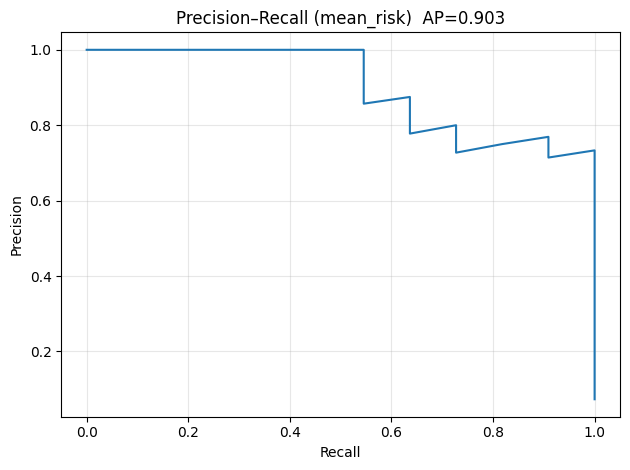

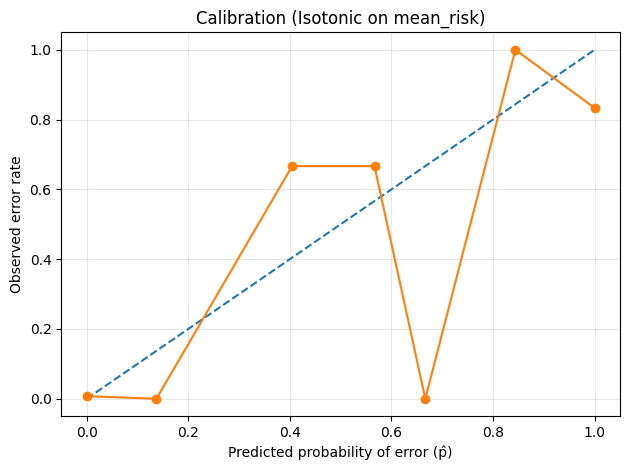

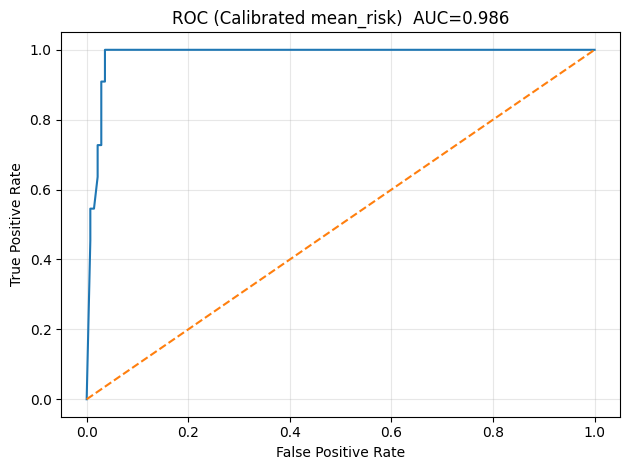

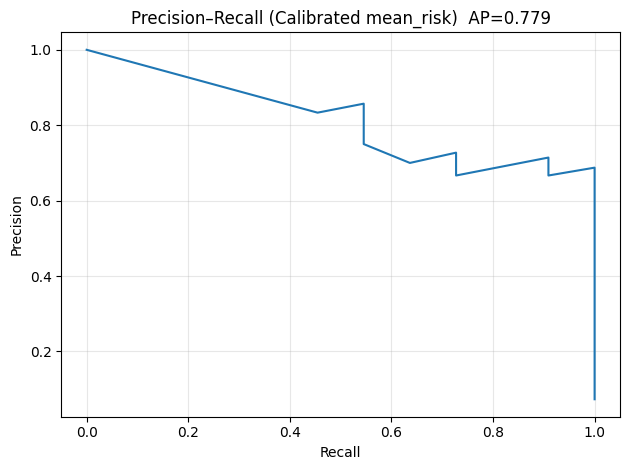

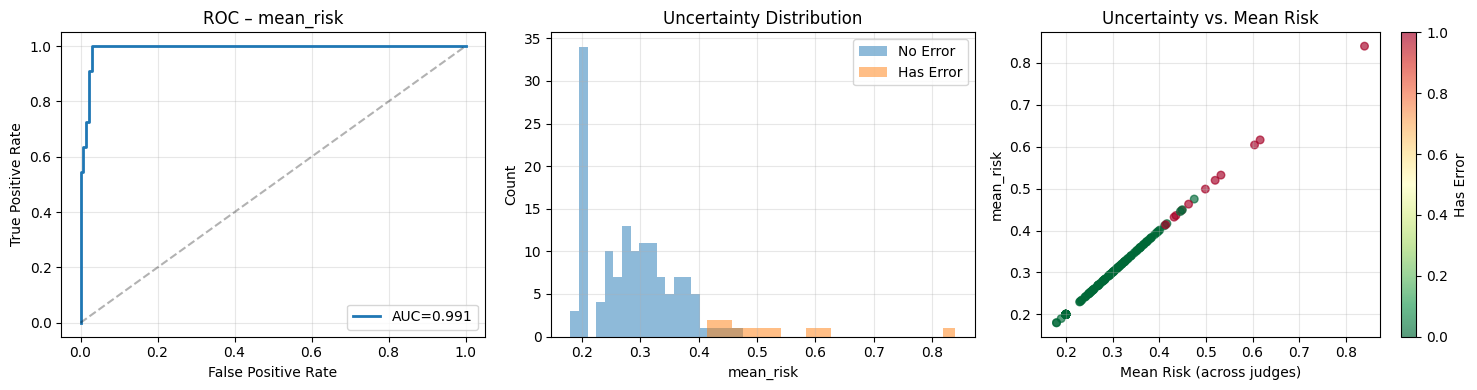

In [ ]:
# ===========================
# Single-cell uncertainty pipeline (risk + disagreement + calibration)
# ===========================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, precision_recall_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import KFold

# ------------- Configuration -------------
# independent acceptance label
LABEL_COL = "hybrid_score"
LABEL_THR = 0.60

# Judges to include in the uncertainty pool (exclude LABEL_COL to avoid leakage)
CANDIDATE_JUDGES = [
    "structural_f1_score",
    "semantic_similarity_score",
    "completeness_score",
    "graph_edit_distance_score",
    # "parse_success_score",
    "openai_issues_score",
    "gemini_changes_score",
]

# Orientation of each judge
ORIENT = {
    "structural_f1_score": "higher_better",
    "semantic_similarity_score": "higher_better",
    "completeness_score": "higher_better",
    "graph_edit_distance_score": "higher_better",
    "hybrid_score": "higher_better",
    "parse_success_score": "higher_better",
    "openai_issues_score": "higher_worse",
    "gemini_changes_score": "higher_worse",
}

# Output file names
ENRICHED_CSV = "judge_scores_with_uncertainties.csv"
COMPARISON_CSV = "uncertainty_metrics_comparison.csv"
CALIBRATED_CSV = "calibrated_probabilities.csv"
FIG_RELIABILITY = "Figure_Calibration_Reliability.png"
FIG_ROC = "Figure_ROC.png"
FIG_PR = "Figure_PR.png"
FIG_TRIPTYCH = "uncertainty_analysis.png"

# ------------- Load df -------------
_g = globals()
if "df" not in _g or not isinstance(_g["df"], pd.DataFrame):
    assert CSV_PATH is not None, "df not found in memory; set CSV_PATH to your scores CSV."
    df = pd.read_csv(CSV_PATH)

print(f"DataFrame shape: {df.shape}")
print(f"Columns: {list(df.columns)}\n")

# ------------- Utilities -------------
def shannon_entropy(p):
    p = np.asarray(p, dtype=float)
    p = p[p > 0]
    if p.size == 0:
        return 0.0
    return float(-(p * np.log(p)).sum())

def to_risk(colname, s):
    """
    Map raw judge score -> risk in [0,1], higher = more likely error.
    """
    orient = ORIENT.get(colname, "higher_better")
    x = np.asarray(s, dtype=float)
    if orient == "higher_better":
        return 1.0 - x
    elif orient == "higher_worse":
        return x
    elif orient == "distance":
        return x / (1.0 + x)
    else:
        return 1.0 - x

def compute_uncertainties_on_risk(risks):
    """
    risks: 1D array of judge risks in [0,1]
    Returns the 8 disagreement features + mean_risk, n_judges.
    """
    r = np.asarray(risks, dtype=float)
    r = r[np.isfinite(r)]
    if r.size == 0:
        return dict(cv=np.nan, entropy=np.nan, range=np.nan, pairwise=np.nan,
                    margin=np.nan, iqr=np.nan, variance=np.nan, std=np.nan,
                    n_judges_used=0, mean_risk=np.nan)
    mean_risk = r.mean()
    std = r.std()
    cv = std / (mean_risk + 1e-8) if mean_risk > 1e-8 else 0.0
    # Entropy on normalized risks
    r_norm = r / (r.sum() + 1e-8)
    ent = shannon_entropy(r_norm) if r.sum() > 0 else 0.0
    rng = r.max() - r.min() if r.size > 1 else 0.0
    if r.size >= 2:
        pair = np.mean([abs(a - b) for a, b in combinations(r, 2)])
        # margin on "confidence" = 1 - risk, then invert
        conf = 1.0 - r
        conf_sorted = np.sort(conf)[::-1]
        margin_unc = 1.0 - (conf_sorted[0] - conf_sorted[1]) if conf_sorted.size >= 2 else 0.0
    else:
        pair, margin_unc = 0.0, 0.0
    iqr = (np.percentile(r, 75) - np.percentile(r, 25)) if r.size >= 4 else 0.0
    var = r.var()
    return dict(cv=cv, entropy=ent, range=rng, pairwise=pair, margin=margin_unc,
                iqr=iqr, variance=var, std=std, n_judges_used=r.size, mean_risk=mean_risk)

def compute_ece(y_true, p_hat, n_bins=10, strategy="equal_width"):
    """
    Expected Calibration Error with equal-width or quantile bins.
    """
    y_true = np.asarray(y_true).astype(int)
    p_hat = np.asarray(p_hat).astype(float)
    if strategy == "equal_width":
        bins = np.linspace(0.0, 1.0, n_bins + 1)
        right = False
    elif strategy == "quantile":
        bins = np.quantile(p_hat, np.linspace(0.0, 1.0, n_bins + 1))
        bins = np.unique(bins)
        if len(bins) <= 2:
            bins = np.linspace(0.0, 1.0, n_bins + 1)
        right = True
    else:
        raise ValueError("strategy must be 'equal_width' or 'quantile'")
    bin_ids = np.digitize(p_hat, bins, right=right) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)
    ece = 0.0
    points = []
    for b in range(bin_ids.min(), bin_ids.max() + 1):
        mask = (bin_ids == b)
        if not np.any(mask):
            continue
        conf = p_hat[mask].mean()
        acc = y_true[mask].mean()
        w = mask.mean()
        ece += w * abs(acc - conf)
        points.append((conf, acc))
    return float(ece), points

def isotonic_cv(predictor, y, n_splits=5, random_state=42):
    """
    Out-of-sample isotonic calibration on a single predictor.
    """
    x = np.asarray(predictor, float)
    y = np.asarray(y, int)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    p_cal = np.zeros_like(x, dtype=float)
    for tr, te in kf.split(x):
        iso = IsotonicRegression(out_of_bounds="clip")
        iso.fit(x[tr], y[tr])
        p_cal[te] = iso.transform(x[te])
    return p_cal

# ------------- Prepare columns -------------
assert LABEL_COL in df.columns, f"Missing label column: {LABEL_COL}"
JUDGE_COLUMNS = [c for c in CANDIDATE_JUDGES if c in df.columns and c != LABEL_COL]
missing = [c for c in CANDIDATE_JUDGES if c not in df.columns]
if missing:
    print("⚠️ Missing judge columns (ignored):", missing)
print(f"Using {len(JUDGE_COLUMNS)} judges:", JUDGE_COLUMNS)

# ------------- Build label y (independent of the judges used) -------------
y = (df[LABEL_COL].astype(float) < LABEL_THR).astype(int)  # 1 = error
print(f"Label (1=error) rate from {LABEL_COL}<{LABEL_THR}: {y.mean():.3f}\n")

# ------------- Compute per-row risks + disagreement metrics -------------
rows = []
risk_cols = []
for col in JUDGE_COLUMNS:
    # store risk per judge as a column for transparency
    r = to_risk(col, df[col].values)
    risk_col = f"risk__{col}"
    df[risk_col] = r
    risk_cols.append(risk_col)

for i, row in df.iterrows():
    risks = [row[c] for c in risk_cols if pd.notna(row[c])]
    rows.append(compute_uncertainties_on_risk(risks))

unc_df = pd.DataFrame(rows).fillna(np.nan)
for c in unc_df.columns:
    df[c] = unc_df[c].values

print("✓ Computed disagreement metrics on risk")
print(unc_df.describe()[["mean_risk","std","cv","variance","entropy","range","pairwise","margin","iqr"]])

# ------------- Discrimination: AUC & AUPRC for each metric -------------
eval_df = df.loc[~y.isna()].copy()
metrics = ["mean_risk","variance","std","cv","entropy","range","pairwise","margin","iqr"]
results = []
for m in metrics:
    s = eval_df[m].astype(float)
    mask = s.notna()
    if mask.sum() < 10:
        continue
    try:
        auc = roc_auc_score(y[mask], s[mask])
        ap = average_precision_score(y[mask], s[mask])
        results.append({"Metric": m, "AUC": float(auc), "AP": float(ap), "N": int(mask.sum())})
    except Exception as e:
        print(f"{m}: error computing AUC/AP -> {e}")

results_df = pd.DataFrame(results).sort_values("AUC", ascending=False)
print("\n📊 Disagreement metrics ranked by AUC:")
print(results_df.to_string(index=False))

best_metric = results_df.iloc[0]["Metric"]
best_scores = df[best_metric].astype(float).values
mask_b = np.isfinite(best_scores)
ap_b = average_precision_score(y[mask_b], best_scores[mask_b])
prec_b, rec_b, _ = precision_recall_curve(y[mask_b], best_scores[mask_b])
plt.figure()
plt.plot(rec_b, prec_b)
plt.title(f"Precision–Recall ({best_metric})  AP={ap_b:.3f}")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(f"Figure_PR_{best_metric}.png", dpi=200)
print("Saved:", f"Figure_PR_{best_metric}.png")

# ------------- Calibrate a probability of error from mean_risk -------------
p_mean = df["mean_risk"].astype(float).values
p_cal = isotonic_cv(p_mean, y.values, n_splits=5, random_state=42)

# Calibration metrics
ece_eq, pts_eq = compute_ece(y.values, p_cal, n_bins=10, strategy="equal_width")
ece_qt, pts_qt = compute_ece(y.values, p_cal, n_bins=10, strategy="quantile")
auc_cal = roc_auc_score(y, p_cal)
ap_cal = average_precision_score(y, p_cal)
print(f"\nCalibrated probability (from mean_risk): AUC={auc_cal:.3f}  AP={ap_cal:.3f}  "
      f"ECE_equal={ece_eq:.3f}  ECE_quantile={ece_qt:.3f}")

# ------------- Figures -------------
# (1) Reliability
plt.figure()
plt.plot([0,1],[0,1], linestyle="--")
if pts_eq:
    xs, ys = zip(*pts_eq)
    plt.plot(xs, ys, marker="o")
plt.title("Calibration (Isotonic on mean_risk)")
plt.xlabel("Predicted probability of error (p̂)")
plt.ylabel("Observed error rate")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_RELIABILITY, dpi=200)
print("Saved:", FIG_RELIABILITY)

# (2) ROC
fpr, tpr, _ = roc_curve(y, p_cal)
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0,1],[0,1], linestyle="--")
plt.title(f"ROC (Calibrated mean_risk)  AUC={auc_cal:.3f}")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_ROC, dpi=200)
print("Saved:", FIG_ROC)

# (3) PR
prec, rec, _ = precision_recall_curve(y, p_cal)
plt.figure()
plt.plot(rec, prec)
plt.title(f"Precision–Recall (Calibrated mean_risk)  AP={ap_cal:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_PR, dpi=200)
print("Saved:", FIG_PR)

# (4) Triptych: best disagreement metric visualization
if len(results_df) > 0:
    best_metric = results_df.iloc[0]["Metric"]
    best_auc = results_df.iloc[0]["AUC"]
    df_plot = eval_df.dropna(subset=[best_metric]).copy()
    fpr_b, tpr_b, _ = roc_curve(y.loc[df_plot.index], df_plot[best_metric].values)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # ROC
    axes[0].plot(fpr_b, tpr_b, linewidth=2, label=f"AUC={best_auc:.3f}")
    axes[0].plot([0,1],[0,1],"k--",alpha=0.3)
    axes[0].set_xlabel("False Positive Rate")
    axes[0].set_ylabel("True Positive Rate")
    axes[0].set_title(f"ROC – {best_metric}")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Distributions
    e_mask = y.loc[df_plot.index] == 1
    axes[1].hist(df_plot.loc[~e_mask, best_metric], bins=20, alpha=0.5, label="No Error")
    axes[1].hist(df_plot.loc[e_mask, best_metric],  bins=20, alpha=0.5, label="Has Error")
    axes[1].set_xlabel(best_metric)
    axes[1].set_ylabel("Count")
    axes[1].set_title("Uncertainty Distribution")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    # Scatter vs mean risk
    sc = axes[2].scatter(df_plot["mean_risk"], df_plot[best_metric],
                         c=y.loc[df_plot.index], cmap="RdYlGn_r", alpha=0.65, s=30)
    axes[2].set_xlabel("Mean Risk (across judges)")
    axes[2].set_ylabel(best_metric)
    axes[2].set_title("Uncertainty vs. Mean Risk")
    axes[2].grid(alpha=0.3)
    cbar = plt.colorbar(sc, ax=axes[2])
    cbar.set_label("Has Error")

    plt.tight_layout()
    plt.savefig(FIG_TRIPTYCH, dpi=300, bbox_inches="tight")
    print("Saved:", FIG_TRIPTYCH)

# ------------- Save outputs -------------
# Merge calibrated probability
df["p_error_hat_mean_risk"] = p_mean
df["p_error_hat_calibrated"] = p_cal
df["has_error_label"] = y.values

# Full dataframe with risks & uncertainties
df.to_csv(ENRICHED_CSV, index=False)
print("\nSaved enriched CSV ->", ENRICHED_CSV)

# Comparison table
results_df.to_csv(COMPARISON_CSV, index=False)
print("Saved comparison CSV ->", COMPARISON_CSV)

# Calibrated probs
pd.DataFrame({
    "p_mean_risk": p_mean,
    "p_calibrated": p_cal,
    "y_true": y.values
}).to_csv(CALIBRATED_CSV, index=False)
print("Saved calibrated probabilities ->", CALIBRATED_CSV)

print("\nDone.")


In [ ]:
# ==== Leakage checks & no-leak ablations ====
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.stats import spearmanr

# 1) Leakage check
rho, pval = spearmanr(1.0 - df["hybrid_score"].astype(float), df["mean_risk"].astype(float), nan_policy="omit")
print(f"Spearman rho(mean_risk, 1-hybrid): {rho:.4f}  (p={pval:.2e})")

# 2) No-S&S ablation: drop structural & semantic from judge pool, recompute mean_risk_only
DROP = {"structural_f1_score","semantic_similarity_score"}
risk_cols = [c for c in df.columns if c.startswith("risk__")]
risk_cols_noSS = [c for c in risk_cols if c.replace("risk__","") not in DROP]
mean_risk_noSS = df[risk_cols_noSS].mean(axis=1)

# Evaluate against the SAME label y (hybrid<thr)
y = df["has_error_label"].astype(int)
mask = mean_risk_noSS.notna()
auc_noSS = roc_auc_score(y[mask], mean_risk_noSS[mask])
ap_noSS  = average_precision_score(y[mask], mean_risk_noSS[mask])
print(f"No-S&S mean_risk: AUC={auc_noSS:.3f}  AP={ap_noSS:.3f}  (judges used: {len(risk_cols_noSS)})")

# 3) Alternate-label ablation: label from StructuralF1, exclude StructuralF1 from predictors
ALT_LABEL = (df["structural_f1_score"].astype(float) < 0.90).astype(int)
risk_cols_noStruct = [c for c in risk_cols if c != "risk__structural_f1_score"]
mean_risk_noStruct = df[risk_cols_noStruct].mean(axis=1)
mask2 = mean_risk_noStruct.notna()
auc_alt = roc_auc_score(ALT_LABEL[mask2], mean_risk_noStruct[mask2])
ap_alt  = average_precision_score(ALT_LABEL[mask2], mean_risk_noStruct[mask2])
print(f"Alt-label (StructF1<0.90), predictors exclude StructF1: AUC={auc_alt:.3f}  AP={ap_alt:.3f}")


Spearman rho(mean_risk, 1-hybrid): 0.9441  (p=3.33e-73)
No-S&S mean_risk: AUC=0.941  AP=0.700  (judges used: 4)
Alt-label (StructF1<0.90), predictors exclude StructF1: AUC=0.901  AP=0.942


In [ ]:
# ==========================================
# Bootstrap CIs + LOJO + Threshold policy
# ==========================================
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt

# --------- Checks ---------
assert "p_error_hat_calibrated" in df.columns, "Expected df['p_error_hat_calibrated'] (run the previous cell first)."
assert "has_error_label" in df.columns, "Expected df['has_error_label'] (run the previous cell first)."

y = df["has_error_label"].astype(int).values
p = df["p_error_hat_calibrated"].astype(float).values
n = len(y)
n_pos = int(y.sum())
n_neg = int((1 - y).sum())
print(f"n={n}, positives={n_pos}, negatives={n_neg}")

# --------- ECE (same definition as earlier, re-declared for isolation) ---------
def compute_ece(y_true, p_hat, n_bins=10, strategy="equal_width"):
    y_true = np.asarray(y_true).astype(int)
    p_hat = np.asarray(p_hat).astype(float)
    if strategy == "equal_width":
        bins = np.linspace(0.0, 1.0, n_bins + 1); right=False
    elif strategy == "quantile":
        bins = np.quantile(p_hat, np.linspace(0.0, 1.0, n_bins + 1))
        bins = np.unique(bins)
        if len(bins) <= 2:
            bins = np.linspace(0.0, 1.0, n_bins + 1)
        right=True
    else:
        raise ValueError("strategy must be 'equal_width' or 'quantile'")
    bin_ids = np.digitize(p_hat, bins, right=right) - 1
    bin_ids = np.clip(bin_ids, 0, len(bins) - 2)
    ece = 0.0
    for b in range(bin_ids.min(), bin_ids.max() + 1):
        m = (bin_ids == b)
        if not np.any(m):
            continue
        conf = p_hat[m].mean()
        acc  = y_true[m].mean()
        w    = m.mean()
        ece += w * abs(acc - conf)
    return float(ece)

# --------- Point metrics ---------
auc_point = roc_auc_score(y, p)
ap_point  = average_precision_score(y, p)
ece_eq_point = compute_ece(y, p, n_bins=10, strategy="equal_width")
ece_qt_point = compute_ece(y, p, n_bins=10, strategy="quantile")
print({"AUC": round(auc_point,4), "AP": round(ap_point,4), "ECE_eq": round(ece_eq_point,4), "ECE_qt": round(ece_qt_point,4)})

# --------- Bootstrap CIs ---------
def bootstrap_cis(y, s, B=2000, seed=42):
    rng = np.random.default_rng(seed)
    aucs, aps, ece_eqs, ece_qts = [], [], [], []
    n = len(y)
    for _ in range(B):
        idx = rng.integers(0, n, size=n)
        yb, sb = y[idx], s[idx]
        if yb.min() == yb.max():
            continue
        try:
            aucs.append(roc_auc_score(yb, sb))
        except Exception:
            pass
        aps.append(average_precision_score(yb, sb))
        ece_eqs.append(compute_ece(yb, sb, n_bins=10, strategy="equal_width"))
        ece_qts.append(compute_ece(yb, sb, n_bins=10, strategy="quantile"))
    def ci(a):
        a = np.asarray(a, float)
        a = a[np.isfinite(a)]
        if a.size == 0:
            return (np.nan, np.nan)
        return (float(np.quantile(a, 0.025)), float(np.quantile(a, 0.975)))
    return {
        "auc_ci": ci(aucs),
        "ap_ci": ci(aps),
        "ece_eq_ci": ci(ece_eqs),
        "ece_qt_ci": ci(ece_qts),
        "n_valid_auc_boot": len(aucs),
        "n_boot": B
    }

cis = bootstrap_cis(y, p, B=2000, seed=123)
print("Bootstrap CIs:", cis)

# Save CI summary
ci_df = pd.DataFrame([{
    "AUC": auc_point, "AUC_lo": cis["auc_ci"][0], "AUC_hi": cis["auc_ci"][1],
    "AP": ap_point,   "AP_lo": cis["ap_ci"][0],   "AP_hi": cis["ap_ci"][1],
    "ECE_eq": ece_eq_point, "ECE_eq_lo": cis["ece_eq_ci"][0], "ECE_eq_hi": cis["ece_eq_ci"][1],
    "ECE_qt": ece_qt_point, "ECE_qt_lo": cis["ece_qt_ci"][0], "ECE_qt_hi": cis["ece_qt_ci"][1],
    "n": n, "n_pos": n_pos, "n_neg": n_neg, "n_valid_auc_boot": cis["n_valid_auc_boot"], "B": cis["n_boot"]
}])
CI_CSV = "uncertainty_bootstrap_cis.csv"
ci_df.to_csv(CI_CSV, index=False)
print("Saved:", CI_CSV)

# --------- LOJO (Leave-One-Judge-Out) with re-calibration ---------
def isotonic_cv(x, y, n_splits=5, seed=42):
    x = np.asarray(x, float); y = np.asarray(y, int)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    out = np.zeros_like(x, dtype=float)
    for tr, te in kf.split(x):
        iso = IsotonicRegression(out_of_bounds="clip")
        iso.fit(x[tr], y[tr])
        out[te] = iso.transform(x[te])
    return out

# Identify per-judge risk columns created earlier
risk_cols = [c for c in df.columns if c.startswith("risk__")]
assert len(risk_cols) >= 2, "Need at least 2 risk__* columns for LOJO."

# Baseline metrics (already calibrated)
auc_base = auc_point
ap_base  = ap_point

lojo_rows = []
for rc in risk_cols:
    keep = [c for c in risk_cols if c != rc]
    mean_risk_excl = df[keep].mean(axis=1).values
    p_cal_excl = isotonic_cv(mean_risk_excl, y, n_splits=5, seed=123)
    auc_excl = roc_auc_score(y, p_cal_excl)
    ap_excl  = average_precision_score(y, p_cal_excl)
    lojo_rows.append({
        "dropped_judge": rc.replace("risk__",""),
        "n_judges_remaining": len(keep),
        "AUC_excl": float(auc_excl),
        "AP_excl": float(ap_excl),
        "Delta_AUC": float(auc_excl - auc_base),
        "Delta_AP": float(ap_excl - ap_base),
    })

lojo_df = pd.DataFrame(lojo_rows).sort_values("AUC_excl", ascending=False)
LOJO_CSV = "lojo_table.csv"
lojo_df.to_csv(LOJO_CSV, index=False)
print("Saved:", LOJO_CSV)
print("\nLOJO summary:\n", lojo_df.to_string(index=False))

# --------- Threshold policy table (budget -> recall/precision/FPR) ---------
def threshold_policy(y, p, budgets=None):
    y = np.asarray(y, int); p = np.asarray(p, float)
    n = len(y)
    if budgets is None:
        budgets = [0.01,0.02,0.05,0.10,0.15,0.20,0.25,0.30,0.40,0.50]
    order = np.argsort(-p)  # descending by risk
    p_sorted = p[order]; y_sorted = y[order]
    cum_pos = np.cumsum(y_sorted)
    cum_neg = np.cumsum(1 - y_sorted)
    total_pos = y.sum(); total_neg = (1 - y).sum()
    rows = []
    for b in budgets:
        k = int(np.ceil(b * n))
        k = max(1, min(k, n))
        thr = p_sorted[k-1]
        sel = p >= thr
        # In case of heavy ties at threshold, refine exactly top-k by index as a secondary rule
        if sel.sum() > k:
            sel = np.zeros(n, dtype=bool)
            sel[order[:k]] = True
        tp = int((y[sel] == 1).sum()); fp = int((y[sel] == 0).sum())
        fn = int(total_pos - tp); tn = int(total_neg - fp)
        recall    = tp / total_pos if total_pos > 0 else np.nan
        precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan
        fpr       = fp / total_neg if total_neg > 0 else np.nan
        rows.append({
            "budget_frac": sel.mean(),
            "items_refined": int(sel.sum()),
            "threshold": float(thr),
            "recall_errors": float(recall),
            "precision_among_refined": float(precision),
            "fpr": float(fpr)
        })
    return pd.DataFrame(rows)

policy_df = threshold_policy(y, p)
POLICY_CSV = "threshold_policy_table.csv"
policy_df.to_csv(POLICY_CSV, index=False)
print("Saved:", POLICY_CSV)
print("\nPolicy table (head):\n", policy_df.head().to_string(index=False))

# Also compute minimal budget to hit a target recall
TARGET_RECALL = 0.95
order = np.argsort(-p)
y_sorted = y[order]
cum_pos = np.cumsum(y_sorted)
total_pos = y.sum()
needed = np.searchsorted(cum_pos, int(np.ceil(TARGET_RECALL * total_pos))) + 1  # top-k needed
budget_needed = needed / len(y)
thr_needed = p[order[needed-1]] if needed-1 < len(p) else p[order[-1]]
print(f"\nMin budget to reach recall≥{TARGET_RECALL:.2f}: "
      f"{budget_needed:.3f} (items={needed}/{len(y)}), threshold≈{thr_needed:.4f}")


n=150, positives=11, negatives=139
{'AUC': np.float64(0.9856), 'AP': np.float64(0.7788), 'ECE_eq': 0.0266, 'ECE_qt': 0.01}
Bootstrap CIs: {'auc_ci': (0.9652710785916722, 0.9985198412698412), 'ap_ci': (0.5063338007478633, 0.9814339994370954), 'ece_eq_ci': (0.009998880176350648, 0.05536837018325395), 'ece_qt_ci': (0.003028045044047389, 0.05192230162077004), 'n_valid_auc_boot': 2000, 'n_boot': 2000}
Saved: uncertainty_bootstrap_cis.csv
Saved: lojo_table.csv

LOJO summary:
             dropped_judge  n_judges_remaining  AUC_excl  AP_excl  Delta_AUC  Delta_AP
semantic_similarity_score                   5  0.982341 0.806047  -0.003270  0.027215
       completeness_score                   5  0.976128 0.657525  -0.009483 -0.121307
      openai_issues_score                   5  0.947351 0.796041  -0.038260  0.017209
     gemini_changes_score                   5  0.941138 0.722527  -0.044474 -0.056306
graph_edit_distance_score                   5  0.905821 0.624183  -0.079791 -0.154649
      str

In [ ]:
# =============================
# Better ranking & smooth calibration (Platt) + revised policy
# =============================
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve

assert "mean_risk" in df.columns and "std" in df.columns, "Run the previous cell first."

y = df["has_error_label"].astype(int).values
p_iso = df["p_error_hat_calibrated"].astype(float).values
r_mean = df["mean_risk"].astype(float).values
r_std  = df["std"].astype(float).values

# ---- Platt (logistic) calibration on raw mean risk ----
X = r_mean.reshape(-1,1)
lr = LogisticRegression(max_iter=200, class_weight="balanced", solver="lbfgs")
lr.fit(X, y)
p_platt = lr.predict_proba(X)[:,1]

# Metrics
def pr_metrics(y, s):
    ap = average_precision_score(y, s)
    auc = roc_auc_score(y, s)
    return auc, ap

auc_platt, ap_platt = pr_metrics(y, p_platt)
auc_iso, ap_iso     = pr_metrics(y, p_iso)
print(f"Platt on mean_risk: AUC={auc_platt:.3f}, AP={ap_platt:.3f} | Isotonic: AUC={auc_iso:.3f}, AP={ap_iso:.3f}")

# ---- Revised ranking policies ----
lam = 0.25
rank_blend = r_mean + lam * r_std

def policy_from_scores(y, score, p_report, budgets=None, label=""):
    y = np.asarray(y, int); score = np.asarray(score, float); p_report = np.asarray(p_report, float)
    n = len(y)
    if budgets is None:
        budgets = [0.01,0.02,0.05,0.10,0.15,0.20,0.25,0.30,0.40,0.50,0.60,0.70,0.80,0.90]
    order = np.argsort(-score)
    p_sorted = p_report[order]
    y_sorted = y[order]
    rows = []
    total_pos = y.sum(); total_neg = (1-y).sum()
    for b in budgets:
        k = max(1, int(np.ceil(b*n)))
        sel_idx = order[:k]
        tp = int(y[sel_idx].sum())
        fp = int((1-y[sel_idx]).sum())
        fn = total_pos - tp; tn = total_neg - fp
        recall    = tp/total_pos if total_pos>0 else np.nan
        precision = tp/(tp+fp) if (tp+fp)>0 else np.nan
        fpr       = fp/total_neg if total_neg>0 else np.nan
        thr_rep   = float(p_sorted[k-1])
        rows.append({"policy":label, "budget_frac": k/n, "items_refined": k,
                     "recall_errors": recall, "precision": precision, "fpr": fpr,
                     "reported_threshold": thr_rep})
    return pd.DataFrame(rows)

pol_iso   = policy_from_scores(y, p_iso,   p_iso,   label="rank: isotonic p̂")
pol_mean  = policy_from_scores(y, r_mean,  p_platt, label="rank: mean_risk (report Platt p̂)")
pol_blend = policy_from_scores(y, rank_blend, p_platt, label=f"rank: mean_risk+{lam}·std (report Platt p̂)")

policy_all = pd.concat([pol_iso, pol_mean, pol_blend], ignore_index=True)
policy_all.to_csv("threshold_policy_table_ranked.csv", index=False)
print("\nSaved: threshold_policy_table_ranked.csv")
print(policy_all.groupby("policy").head(6).to_string(index=False))

# ---- Min budget to hit target recall for each ranking ----
def min_budget_for_recall(y, score, target=0.95):
    n = len(y)
    order = np.argsort(-score)
    y_sorted = y[order]
    cum_pos = np.cumsum(y_sorted)
    need = int(np.ceil(target * y.sum()))
    k = int(np.searchsorted(cum_pos, need) + 1)
    k = min(max(1,k), n)
    return k/n, k

for name, s in [("isotonic p̂", p_iso), ("mean_risk", r_mean), (f"mean_risk+{lam}·std", rank_blend)]:
    b,k = min_budget_for_recall(y, s, target=0.95)
    print(f"Min budget for recall≥0.95 using '{name}': {b:.3f} (items={k}/{len(y)})")

# final calibrated probability
df['p_error_hat_final'] = p_platt
print("\nSet df['p_error_hat_final'] = Platt-calibrated probability (smoother ranking).")


Platt on mean_risk: AUC=0.991, AP=0.903 | Isotonic: AUC=0.986, AP=0.779

Saved: threshold_policy_table_ranked.csv
                                    policy  budget_frac  items_refined  recall_errors  precision      fpr  reported_threshold
                         rank: isotonic p̂     0.013333              2       0.181818   1.000000 0.000000            1.000000
                         rank: isotonic p̂     0.020000              3       0.181818   0.666667 0.007194            1.000000
                         rank: isotonic p̂     0.053333              8       0.545455   0.750000 0.014388            0.666667
                         rank: isotonic p̂     0.100000             15       0.909091   0.666667 0.035971            0.137281
                         rank: isotonic p̂     0.153333             23       1.000000   0.478261 0.086331            0.000000
                         rank: isotonic p̂     0.200000             30       1.000000   0.366667 0.136691            0.000000
    

In [ ]:
# ==========================================
# Cost-optimal two-stage refinement policy
# ==========================================
import numpy as np, pandas as pd

assert "p_error_hat_final" in df.columns and "has_error_label" in df.columns, "Run the previous cells first."

# ---- Set your costs here ----
# c_miss: cost of accepting an item that is actually an error (y=1)
# c_cheap: cost of cheap refinement (canonicalize / short prompt)
# c_full: cost of full refinement (expensive agent)
c_miss  = 20.0
c_cheap = 0.5
c_full  = 1.0

y = df["has_error_label"].astype(int).values
p = df["p_error_hat_final"].astype(float).values  # calibrated probability (Platt)
n = len(y)

# tie-breaker rank for display
rank_score = df["mean_risk"].astype(float).values + 0.25 * df["std"].astype(float).values

def policy_cost(y, p, t_accept, t_full):
    """
    Accept if p < t_accept
    Cheap refine if t_accept <= p < t_full
    Full refine if p >= t_full
    Expected cost per item:
      Accept: p * c_miss
      Cheap: c_cheap
      Full:  c_full
    """
    accept = p < t_accept
    cheap  = (p >= t_accept) & (p < t_full)
    full   = p >= t_full

    cost = np.zeros_like(p, dtype=float)
    cost[accept] = p[accept] * c_miss
    cost[cheap]  = c_cheap
    cost[full]   = c_full

    # Diagnostics
    refined = cheap | full
    tp = (y[refined] == 1).sum()
    fp = (y[refined] == 0).sum()
    fn = (y[~refined] == 1).sum()
    tn = (y[~refined] == 0).sum()
    total_pos = y.sum()
    total_neg = (1 - y).sum()

    recall    = tp / total_pos if total_pos>0 else np.nan
    precision = tp / (tp + fp) if (tp + fp)>0 else np.nan
    fpr       = fp / total_neg if total_neg>0 else np.nan
    budget    = refined.mean()

    return cost.mean(), {"recall": recall, "precision": precision, "fpr": fpr,
                         "budget": budget, "t_accept": t_accept, "t_full": t_full}

# Grid search thresholds
grid = np.linspace(0, 1, 201)
best = None
best_diag = None
for ta in grid:
    for tf in grid:
        if tf < ta:
            continue
        c, d = policy_cost(y, p, ta, tf)
        if (best is None) or (c < best):
            best, best_diag = c, d

print("\n=== Cost-optimal two-stage policy ===")
print({k: (round(v,4) if isinstance(v, float) else v) for k, v in best_diag.items()})
print(f"Expected cost per item: {best:.4f}   (c_miss={c_miss}, c_cheap={c_cheap}, c_full={c_full})")

# Show a simple action preview for the optimal thresholds
ta, tf = best_diag["t_accept"], best_diag["t_full"]
actions = np.where(p < ta, "accept", np.where(p < tf, "cheap_refine", "full_refine"))
df_policy = df[["sample_id","contract_id","clause_id"]].copy() if set(["sample_id","contract_id","clause_id"]).issubset(df.columns) else pd.DataFrame(index=df.index)
df_policy["p_hat"] = p
df_policy["rank_score"] = rank_score
df_policy["action"] = actions
# prioritize by action, then descending rank_score
order = np.lexsort((-rank_score, actions))  # actions sorted alphabetically; ensure 'full_refine'/'cheap_refine' at top if desired
preview = df_policy.iloc[order].groupby("action").head(5)
print("\nAction preview (top-5 per action):")
print(preview.to_string(index=False))

# Save the full action plan
df_policy.to_csv("refinement_action_plan.csv", index=False)
print("\nSaved action plan -> refinement_action_plan.csv")



=== Cost-optimal two-stage policy ===
{'recall': np.float64(1.0), 'precision': np.float64(0.0733), 'fpr': np.float64(1.0), 'budget': np.float64(1.0), 't_accept': np.float64(0.0), 't_full': np.float64(0.91)}
Expected cost per item: 0.5000   (c_miss=20.0, c_cheap=0.5, c_full=1.0)

Action preview (top-5 per action):
                                                                                                                             sample_id                                                      contract_id clause_id    p_hat  rank_score       action
INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRANCHISE AGREEMENT/INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRANCHISE_AGREEMENT_15.5.2.4   INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRANCHISE AGREEMENT  15.5.2.4 0.905513    0.920000 cheap_refine
      INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRANCHISE AGREEMENT/INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRANCHISE_AGREEMENT_25   INTERNATIONALFASTFOODCORP_04_04_1997-EX-99-FRANCHISE AGREEM

DataFrame shape: (150, 33)
Total samples: 150

Using 7 judges for uncertainty computation
Judges: ['structural_f1_score', 'semantic_similarity_score', 'completeness_score', 'graph_edit_distance_score', 'hybrid_score', 'openai_issues_score', 'gemini_changes_score']

Computing uncertainties for all samples...
✓ Computed uncertainties for all samples
  6.0 judges used per sample (avg)

Computing error labels...
Error Definition: ANY judge score < 0.5
Samples with errors: 40/150 (26.7%)

AUC COMPARISON FOR DIFFERENT UNCERTAINTY METRICS
variance       : AUC = 0.9298 (n=150)
std            : AUC = 0.9298 (n=150)
cv             : AUC = 0.9820 (n=150)
entropy        : AUC = 0.0170 (n=150)
range          : AUC = 0.9220 (n=150)
pairwise       : AUC = 0.9264 (n=150)
margin         : AUC = 0.2532 (n=150)
iqr            : AUC = 0.8936 (n=150)


📊 RESULTS RANKED BY AUC:
  Metric      AUC   N  Corr_w_Mean
      cv 0.982045 150    -0.788531
variance 0.929773 150    -0.599960
     std 0.929773 150    -

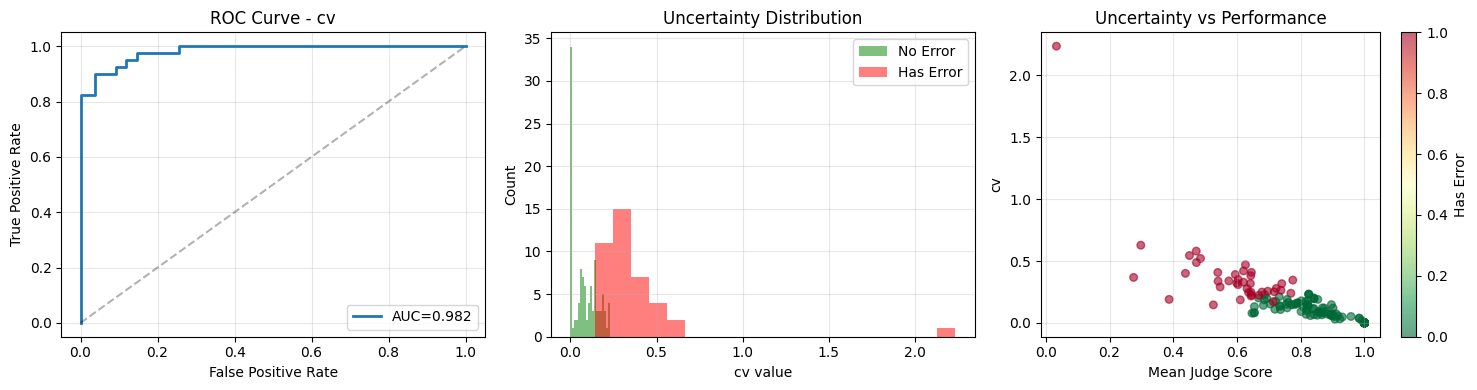


💾 Saved results to: judge_scores_with_uncertainties.csv
💾 Saved comparison to: uncertainty_metrics_comparison.csv

ANALYSIS COMPLETE!


In [ ]:

# ==========================================
# UNCERTAINTY ONLY BASED SIGNAL
# ==========================================

import numpy as np
import pandas as pd
from scipy.stats import entropy
from itertools import combinations
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

print(f"DataFrame shape: {df.shape}")
print(f"Total samples: {len(df)}")
print()

# ============================================================================
# 1. DEFINE ALL UNCERTAINTY METRICS
# ============================================================================

def compute_uncertainties(judge_scores):
    """
    Compute 7 different uncertainty metrics from judge scores.

    Args:
        judge_scores: numpy array of shape (n_judges,) with scores in [0,1]

    Returns:
        dict with all uncertainty metrics
    """
    scores = np.array(judge_scores)

    # Handle edge cases
    if len(scores) == 0:
        return {k: np.nan for k in ['cv', 'entropy', 'range', 'pairwise', 'margin', 'iqr', 'variance', 'std']}

    # 1. Coefficient of Variation
    mean_score = np.mean(scores)
    cv = np.std(scores) / (mean_score + 1e-8) if mean_score > 1e-8 else 0

    # 2. Entropy
    scores_norm = scores / (np.sum(scores) + 1e-8)
    ent = entropy(scores_norm) if np.sum(scores_norm) > 0 else 0

    # 3. Max-Min Range
    range_unc = np.max(scores) - np.min(scores) if len(scores) > 1 else 0

    # 4. Pairwise Disagreement
    if len(scores) >= 2:
        pairwise_diffs = [abs(s1 - s2) for s1, s2 in combinations(scores, 2)]
        pairwise_unc = np.mean(pairwise_diffs)
    else:
        pairwise_unc = 0

    # 5. Ensemble Margin (inverted)
    if len(scores) >= 2:
        sorted_scores = np.sort(scores)[::-1]
        margin = sorted_scores[0] - sorted_scores[1]
        margin_unc = 1 - margin
    else:
        margin_unc = 0

    # 6. IQR
    if len(scores) >= 4:
        q75, q25 = np.percentile(scores, [75, 25])
        iqr = q75 - q25
    else:
        iqr = 0

    # 7. Original Variance (for comparison)
    var = np.var(scores)

    # 8. Standard Deviation (often better than variance)
    std = np.std(scores)

    return {
        'cv': cv,
        'entropy': ent,
        'range': range_unc,
        'pairwise': pairwise_unc,
        'margin': margin_unc,
        'iqr': iqr,
        'variance': var,
        'std': std,
        'n_judges_used': len(scores),
        'mean_score': mean_score
    }


# ============================================================================
# 2. SELECT JUDGES TO USE
# ============================================================================

# Select which judges to include
JUDGE_COLUMNS = [
    'structural_f1_score',
    'semantic_similarity_score',
    'completeness_score',
    'graph_edit_distance_score',
    'hybrid_score',
    # 'parse_success_score',
    'openai_issues_score',
    'gemini_changes_score',
]

print(f"Using {len(JUDGE_COLUMNS)} judges for uncertainty computation")
print(f"Judges: {JUDGE_COLUMNS}\n")


# ============================================================================
# 3. COMPUTE ALL UNCERTAINTIES FOR ALL SAMPLES
# ============================================================================

print("Computing uncertainties for all samples...")

uncertainty_results = []

for idx, row in df.iterrows():
    # Extract judge scores, filtering out None/NaN
    judge_scores = []
    for col in JUDGE_COLUMNS:
        score = row[col]
        if pd.notna(score) and score is not None:
            judge_scores.append(float(score))

    # Compute uncertainties for this row
    uncertainties = compute_uncertainties(judge_scores)
    uncertainty_results.append(uncertainties)

uncertainty_df = pd.DataFrame(uncertainty_results)

for col in uncertainty_df.columns:
    df[col] = uncertainty_df[col].values

print("✓ Computed uncertainties for all samples")
print(f"  {df['n_judges_used'].mean():.1f} judges used per sample (avg)")
print()


# ============================================================================
# 4. DEFINE ERROR LABELS
# ============================================================================

ERROR_THRESHOLD = 0.5

print("Computing error labels...")

error_labels = []

for idx, row in df.iterrows():
    judge_scores = []
    for col in JUDGE_COLUMNS:
        score = row[col]
        if pd.notna(score) and score is not None:
            judge_scores.append(float(score))

    if not judge_scores:
        error_labels.append(np.nan)
        continue

    # Option 1: ANY judge flags error (conservative)
    has_error = int(any(s < ERROR_THRESHOLD for s in judge_scores))

    # Option 2: MEAN score below threshold (lenient) - uncomment to use
    # has_error = int(np.mean(judge_scores) < ERROR_THRESHOLD)

    error_labels.append(has_error)

df['has_error'] = error_labels

print(f"Error Definition: ANY judge score < {ERROR_THRESHOLD}")
print(f"Samples with errors: {df['has_error'].sum()}/{len(df)} ({df['has_error'].mean()*100:.1f}%)")
print()


# ============================================================================
# 5. COMPUTE AUC FOR EACH UNCERTAINTY METRIC
# ============================================================================

# Remove rows with missing error labels
df_eval = df.dropna(subset=['has_error'])

uncertainty_metrics = ['variance', 'std', 'cv', 'entropy', 'range', 'pairwise', 'margin', 'iqr']
results_table = []

print("=" * 70)
print("AUC COMPARISON FOR DIFFERENT UNCERTAINTY METRICS")
print("=" * 70)

for metric in uncertainty_metrics:
    # Skip if all NaN
    if df_eval[metric].isna().all():
        continue

    # Remove NaN for this metric
    df_metric = df_eval.dropna(subset=[metric])

    if len(df_metric) < 10:
        print(f"{metric:15s}: Insufficient data")
        continue

    try:
        auc = roc_auc_score(df_metric['has_error'], df_metric[metric])
        corr_with_mean = df_metric[metric].corr(df_metric['mean_score'])

        results_table.append({
            'Metric': metric,
            'AUC': auc,
            'N': len(df_metric),
            'Corr_w_Mean': corr_with_mean
        })

        print(f"{metric:15s}: AUC = {auc:.4f} (n={len(df_metric)})")

    except Exception as e:
        print(f"{metric:15s}: Error - {e}")

print("=" * 70)
print()

results_df = pd.DataFrame(results_table).sort_values('AUC', ascending=False)

print("\n📊 RESULTS RANKED BY AUC:")
print(results_df.to_string(index=False))
print()


# ============================================================================
# 6. IDENTIFY BEST METRIC
# ============================================================================

if len(results_df) > 0:
    best_metric = results_df.iloc[0]['Metric']
    best_auc = results_df.iloc[0]['AUC']

    print(f"🏆 BEST UNCERTAINTY METRIC: {best_metric}")
    print(f"   AUC = {best_auc:.4f}")

    if best_auc >= 0.7:
        print("   ✅ EXCELLENT - Strong error predictor!")
    elif best_auc >= 0.6:
        print("   ⚠️  MODERATE - Weak but usable signal")
    else:
        print("   ❌ POOR - Not a reliable error predictor")
    print()


    # ============================================================================
    # 7. VISUALIZE BEST METRIC
    # ============================================================================

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # Plot 1: ROC Curve
    df_plot = df_eval.dropna(subset=[best_metric])
    fpr, tpr, thresholds = roc_curve(df_plot['has_error'], df_plot[best_metric])

    axes[0].plot(fpr, tpr, linewidth=2, label=f'AUC={best_auc:.3f}')
    axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.3)
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title(f'ROC Curve - {best_metric}')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Plot 2: Distribution by error status
    df_plot_error = df_plot[df_plot['has_error'] == 1][best_metric]
    df_plot_correct = df_plot[df_plot['has_error'] == 0][best_metric]

    axes[1].hist(df_plot_correct, bins=20, alpha=0.5, label='No Error', color='green')
    axes[1].hist(df_plot_error, bins=20, alpha=0.5, label='Has Error', color='red')
    axes[1].set_xlabel(f'{best_metric} value')
    axes[1].set_ylabel('Count')
    axes[1].set_title(f'Uncertainty Distribution')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    # Plot 3: Uncertainty vs Mean Score
    scatter = axes[2].scatter(df_plot['mean_score'], df_plot[best_metric],
                   c=df_plot['has_error'], cmap='RdYlGn_r', alpha=0.6, s=30)
    axes[2].set_xlabel('Mean Judge Score')
    axes[2].set_ylabel(f'{best_metric}')
    axes[2].set_title('Uncertainty vs Performance')
    axes[2].grid(alpha=0.3)
    cbar = plt.colorbar(scatter, ax=axes[2])
    cbar.set_label('Has Error')

    plt.tight_layout()
    plt.savefig('uncertainty_analysis.png', dpi=300, bbox_inches='tight')
    print("📊 Saved visualization to: uncertainty_analysis.png")
    plt.show()


# ============================================================================
# 8. SAVE RESULTS
# ============================================================================

# Save the full dataframe with all uncertainty metrics
df.to_csv('judge_scores_with_uncertainties.csv', index=False)
print(f"\n💾 Saved results to: judge_scores_with_uncertainties.csv")

# Save the comparison table
results_df.to_csv('uncertainty_metrics_comparison.csv', index=False)
print(f"💾 Saved comparison to: uncertainty_metrics_comparison.csv")

print("\n" + "=" * 70)
print("ANALYSIS COMPLETE!")
print("=" * 70)